Ghi chú ngày 6: Titanic end-to-end — tiền xử lý không rò rỉ, baseline, mô hình, ablation, nộp Kaggle

- Không dùng `sklearn.pipeline`: tự viết preprocessor bằng Pandas + NumPy.
- Quy tắc chống rò rỉ: **mọi thống kê (median, mode, mean/std, danh sách category) chỉ học trên tập train (`tr`)**, rồi dùng lại y nguyên cho `val` và `test`.
- Cần `train.csv` và `test.csv` (tải từ trang Titanic trên Kaggle) đặt cùng thư mục với notebook.

In [1]:
# 0 — Import thư viện
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression          # chỉ để đối chiếu ở Bước 4.2

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 140)

In [2]:
# 0.1 — Dùng lại từ ngày 3–5: add_bias, sigmoid, bce_from_logits, train_gd, LogisticRegressionGD, confusion_counts
def add_bias(X):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    return np.hstack([np.ones((X.shape[0], 1)), X])

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

def bce_from_logits(z, y):
    return np.mean(np.logaddexp(0, z) - y * z)

def train_gd(X, y, loss_fn, grad_fn, w0, lr=0.01, batch_size=None, epochs=50, momentum=0.0, seed=0):
    # batch_size=None: batch GD; 1: SGD; số khác: mini-batch
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    B = n if batch_size is None else batch_size
    w = np.array(w0, dtype=float)
    v = np.zeros_like(w)
    losses = []
    for _ in range(epochs):
        perm = rng.permutation(n)
        for start in range(0, n, B):
            b = perm[start:start + B]
            v = momentum * v - lr * grad_fn(w, X[b], y[b])
            w = w + v
        losses.append(loss_fn(w, X, y))
        if not np.isfinite(losses[-1]):
            break
    return w, losses

class LogisticRegressionGD:
    def __init__(self, lr=0.1, batch_size=None, epochs=100, momentum=0.0, seed=0):
        self.lr, self.batch_size, self.epochs = lr, batch_size, epochs
        self.momentum, self.seed = momentum, seed

    @staticmethod
    def loss(w, X, y):
        return bce_from_logits(X @ w, y)

    @staticmethod
    def grad(w, X, y):
        return X.T @ (sigmoid(X @ w) - y) / len(y)

    def fit(self, X, y):
        Xb = add_bias(X)
        w, self.loss_history_ = train_gd(
            Xb, y, self.loss, self.grad, np.zeros(Xb.shape[1]),
            lr=self.lr, batch_size=self.batch_size, epochs=self.epochs,
            momentum=self.momentum, seed=self.seed)
        self.intercept_, self.coef_ = w[0], w[1:]
        return self

    def decision_function(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

def confusion_counts(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(bool), np.asarray(y_pred).astype(bool)
    tp = np.sum(y_pred & y_true)
    fp = np.sum(y_pred & ~y_true)
    fn = np.sum(~y_pred & y_true)
    tn = np.sum(~y_pred & ~y_true)
    return tp, fp, fn, tn

def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))

## Bước 1 — Chuẩn bị

In [3]:
# 1.1 — Đọc dữ liệu
train_full = pd.read_csv("train.csv")
test_raw = pd.read_csv("test.csv")
print("train:", train_full.shape, "| test:", test_raw.shape)
print("\nGiá trị thiếu (train | test):")
print(pd.concat([train_full.isna().sum(), test_raw.isna().sum()], axis=1, keys=["train", "test"]).query("train > 0 or test > 0"))

train: (891, 12) | test: (418, 11)

Giá trị thiếu (train | test):
          train   test
Age         177   86.0
Fare          0    1.0
Cabin       687  327.0
Embarked      2    0.0


In [4]:
# 1.2 — Chia tr (80%) / val (20%), stratify theo Survived
tr_raw, val_raw = train_test_split(
    train_full, test_size=0.2, stratify=train_full["Survived"], random_state=42)
print("tr:", tr_raw.shape, " val:", val_raw.shape)
print(f"tỉ lệ sống — full: {train_full['Survived'].mean():.4f}  tr: {tr_raw['Survived'].mean():.4f}  val: {val_raw['Survived'].mean():.4f}")

tr: (712, 12)  val: (179, 12)
tỉ lệ sống — full: 0.3838  tr: 0.3834  val: 0.3855


In [5]:
# 1.3 — add_features: chỉ biến đổi từng hàng, không học thống kê nào
#   Ngày 2 gom Title hiếm theo "số lần xuất hiện < 10" — đó là thống kê học từ dữ liệu.
#   Ở đây dùng danh sách cố định để hàm không phụ thuộc vào tập nào (kết quả trùng với ngày 2).
MAIN_TITLES = ["Mr", "Mrs", "Miss", "Master"]

def add_features(df):
    df = df.copy()
    title = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["Title"] = title.where(title.isin(MAIN_TITLES), "Rare")
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    df["HasCabin"] = df["Cabin"].notna().astype(int)
    return df

tr, val, te = add_features(tr_raw), add_features(val_raw), add_features(test_raw)
print(pd.concat([d["Title"].value_counts() for d in (tr, val, te)], axis=1, keys=["tr", "val", "test"]))
tr[["Name", "Title", "SibSp", "Parch", "FamilySize", "IsAlone", "Cabin", "HasCabin"]].head()

         tr  val  test
Title                 
Mr      412  105   240
Miss    144   41    79
Mrs     107   19    72
Master   31    9    21
Rare     18    5     6


,Name,Title,SibSp,Parch,FamilySize,IsAlone,Cabin,HasCabin
692,"Lam, Mr. Ali",Mr,0,0,1,1,NaN,0
481,"Frost, Mr. Anthony Wood ""Archie""",Mr,0,0,1,1,NaN,0
527,"Farthing, Mr. John",Mr,0,0,1,1,C95,1
855,"Aks, Mrs. Sam (Leah Rosen)",Mrs,0,1,2,0,NaN,0
801,"Collyer, Mrs. Harvey (Charlotte Annie Tate)",Mrs,1,1,3,0,NaN,0


## Bước 2 — Preprocessor không rò rỉ

In [6]:
# 2.1 — TitanicPreprocessor
#   fit(df)       : học thống kê trên df (chỉ gọi với tập train)
#   transform(df) : dùng lại thống kê đã học → ma trận số, không còn nan
NUM_COLS = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]      # chuẩn hóa (Fare dùng log1p trước)
BIN_COLS = ["IsAlone", "HasCabin"]                              # đã là 0/1, giữ nguyên
CAT_COLS = ["Pclass", "Sex", "Embarked", "Title"]               # one-hot

class TitanicPreprocessor:
    def __init__(self, num_cols=NUM_COLS, bin_cols=BIN_COLS, cat_cols=CAT_COLS):
        self.num_cols, self.bin_cols, self.cat_cols = list(num_cols), list(bin_cols), list(cat_cols)

    def _impute(self, df):
        df = df.copy()
        # Age: median theo Title (học trên train), Title lạ → median chung
        age_fill = df["Title"].map(self.age_by_title_).fillna(self.age_median_)
        df["Age"] = df["Age"].fillna(age_fill)
        df["Fare"] = np.log1p(df["Fare"].fillna(self.fare_median_))
        df["Embarked"] = df["Embarked"].fillna(self.embarked_mode_)
        return df

    def fit(self, df):
        # 1) thống kê để điền giá trị thiếu
        self.age_by_title_ = df.groupby("Title")["Age"].median()
        self.age_median_ = df["Age"].median()
        self.fare_median_ = df["Fare"].median()
        self.embarked_mode_ = df["Embarked"].mode()[0]
        d = self._impute(df)
        # 2) danh sách category cho one-hot (category chỉ có ở test → toàn 0)
        self.categories_ = {c: sorted(d[c].unique()) for c in self.cat_cols}
        # 3) mean/std cho cột số
        num = d[self.num_cols].to_numpy(dtype=float)
        self.mean_ = num.mean(axis=0)
        self.scale_ = num.std(axis=0)
        self.scale_[self.scale_ == 0] = 1.0
        self.feature_names_ = (self.num_cols + self.bin_cols
                               + [f"{c}_{v}" for c in self.cat_cols for v in self.categories_[c]])
        return self

    def transform(self, df):
        d = self._impute(df)
        parts = [(d[self.num_cols].to_numpy(dtype=float) - self.mean_) / self.scale_,
                 d[self.bin_cols].to_numpy(dtype=float)]
        for c in self.cat_cols:
            cats = np.array(self.categories_[c])
            parts.append((d[c].to_numpy()[:, None] == cats[None, :]).astype(float))
        return np.hstack(parts)

    def fit_transform(self, df):
        return self.fit(df).transform(df)

In [7]:
# 2.2 — fit trên tr, transform cho tr / val / test
prep = TitanicPreprocessor().fit(tr)
X_tr, X_val, X_te = prep.transform(tr), prep.transform(val), prep.transform(te)
y_tr, y_val = tr["Survived"].to_numpy(), val["Survived"].to_numpy()

print("shape — tr:", X_tr.shape, " val:", X_val.shape, " test:", X_te.shape)
assert X_tr.shape[1] == X_val.shape[1] == X_te.shape[1], "Số cột khác nhau!"
assert not any(np.isnan(X).any() for X in (X_tr, X_val, X_te)), "Còn nan!"
print("OK: cùng số cột, không có nan")
print(f"\n{len(prep.feature_names_)} đặc trưng:", prep.feature_names_)

print("\nThống kê học từ tr:")
print("  median Age theo Title:", prep.age_by_title_.round(1).to_dict())
print(f"  median Fare = {prep.fare_median_:.4f},  mode Embarked = {prep.embarked_mode_}")
print("  mean cột số:", dict(zip(prep.num_cols, prep.mean_.round(3))))
print("\nmean / std các cột đã chuẩn hóa — tr:", X_tr[:, :5].mean(0).round(3), X_tr[:, :5].std(0).round(3))
print("                                 val:", X_val[:, :5].mean(0).round(3), X_val[:, :5].std(0).round(3))

shape — tr: (712, 20)  val: (179, 20)  test: (418, 20)
OK: cùng số cột, không có nan

20 đặc trưng: ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']

Thống kê học từ tr:
  median Age theo Title: {'Master': 3.0, 'Miss': 22.0, 'Mr': 30.0, 'Mrs': 35.0, 'Rare': 49.0}
  median Fare = 14.4542,  mode Embarked = S
  mean cột số: {'Age': np.float64(29.557), 'SibSp': np.float64(0.493), 'Parch': np.float64(0.39), 'Fare': np.float64(2.951), 'FamilySize': np.float64(1.883)}

mean / std các cột đã chuẩn hóa — tr: [ 0. -0.  0.  0. -0.] [1. 1. 1. 1. 1.]
                                 val: [-0.047  0.141 -0.053  0.058  0.066] [0.999 1.178 0.791 0.944 1.073]


**Nhận xét 2:**
- Ba ma trận cùng 20 cột và không còn nan. Category được cố định lúc `fit`, nên test có Title hoặc Embarked lạ cũng không sinh thêm cột.
- Sau chuẩn hóa, cột số trên **tr** có mean = 0, std = 1 chính xác, còn trên **val** thì lệch một chút (mean ±0.14, std 0.79–1.18). Đây là dấu hiệu **đúng**: val được biến đổi bằng mean/std của tr, không phải của chính nó. Nếu val cũng ra đúng 0/1 thì nghĩa là đã fit trên val, tức là rò rỉ.
- Median Age theo Title học từ tr: Master 3, Miss 22, Mr 30, Mrs 35, Rare 49. Điền theo Title tốt hơn nhiều so với một median chung 28: một bé trai thiếu tuổi sẽ được điền 3 thay vì 28.

## Bước 3 — Baseline

In [8]:
# 3.1 — Luôn dự đoán 0 (chết);  3.2 — nữ = 1, nam = 0
acc_zero = accuracy(y_val, np.zeros_like(y_val))
acc_sex = accuracy(y_val, (val["Sex"] == "female").astype(int))
print(f"Baseline luôn 0      : {acc_zero:.4f}")
print(f"Baseline giới tính   : {acc_sex:.4f}")
print(f"(1 hành khách trong val = {1 / len(y_val):.2%} accuracy)")

Baseline luôn 0      : 0.6145
Baseline giới tính   : 0.7765
(1 hành khách trong val = 0.56% accuracy)


## Bước 4 — Mô hình

In [9]:
# 4.1 — Thử 3 learning rate × 2 batch size, chọn theo accuracy trên val
#   Hòa accuracy thì chọn cấu hình có BCE trên val thấp hơn.
EPOCHS = 200
results, models = [], {}
for lr in [0.01, 0.1, 1.0]:
    for bs in [32, None]:
        m = LogisticRegressionGD(lr=lr, batch_size=bs, epochs=EPOCHS, seed=0).fit(X_tr, y_tr)
        models[(lr, bs)] = m
        results.append({
            "lr": lr, "batch_size": "full" if bs is None else bs,
            "train_acc": accuracy(y_tr, m.predict(X_tr)),
            "val_acc": accuracy(y_val, m.predict(X_val)),
            "val_bce": bce_from_logits(m.decision_function(X_val), y_val),
        })
grid = pd.DataFrame(results)
best_row = grid.sort_values(["val_acc", "val_bce"], ascending=[False, True]).iloc[0]
best_cfg = {"lr": float(best_row["lr"]),
            "batch_size": None if best_row["batch_size"] == "full" else int(best_row["batch_size"]),
            "epochs": EPOCHS, "seed": 0}
clf = models[(best_cfg["lr"], best_cfg["batch_size"])]
print("Cấu hình tốt nhất:", best_cfg)
grid.round(4)

Cấu hình tốt nhất: {'lr': 0.1, 'batch_size': 32, 'epochs': 200, 'seed': 0}


,lr,batch_size,train_acc,val_acc,val_bce
0,0.01,32,0.8216,0.8156,0.4372
1,0.01,full,0.7711,0.7598,0.5541
2,0.10,32,0.8272,0.8436,0.4262
3,0.10,full,0.8160,0.8268,0.4483
4,1.00,32,0.8216,0.8156,0.4319
5,1.00,full,0.8287,0.8324,0.4294


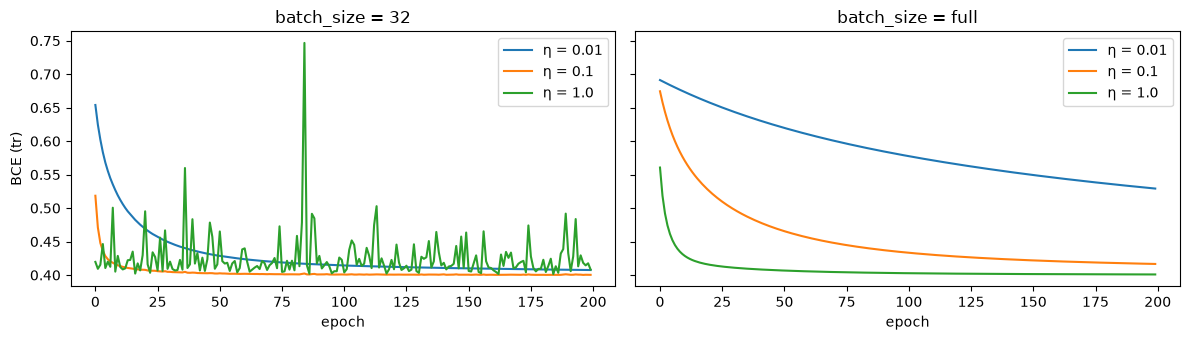

In [10]:
# 4.1b — Loss train theo epoch của 6 cấu hình
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, bs in zip(axes, [32, None]):
    for lr in [0.01, 0.1, 1.0]:
        ax.plot(models[(lr, bs)].loss_history_, label=f"η = {lr}")
    ax.set_title(f"batch_size = {'full' if bs is None else bs}")
    ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("BCE (tr)")
plt.tight_layout(); plt.show()

**Nhận xét 4.1:**
- Cấu hình tốt nhất: **η = 0.1, mini-batch 32**, val accuracy **0.8436**, vượt baseline giới tính (0.7765) khoảng 12 hành khách.
- η = 0.01 với full batch bị **underfit** (val 0.76): 200 epoch × 1 bước/epoch chỉ là 200 bước nhỏ, loss vẫn đang giảm. Cùng η = 0.01 nhưng mini-batch 32 thì có 23 bước/epoch, tức 4.600 bước, nên đã gần hội tụ (0.8156).
- η = 1.0 vẫn không phân kỳ: dữ liệu đã chuẩn hóa và BCE lồi với độ cong nhỏ, nên bước lớn vẫn an toàn. Riêng với mini-batch, loss dao động hơn.
- Năm cấu hình hội tụ chỉ chênh nhau 0.8156–0.8436, tức **5 hành khách** trên 179. Với val nhỏ như vậy, chênh 1–2 người là nhiễu, không nên tin là cấu hình này chắc chắn hơn cấu hình kia.

In [11]:
# 4.2 — sklearn LogisticRegression trên cùng X_tr / X_val
#   Mặc định có L2 (C = 1). Thêm bản không regularize (C = ∞) để so với GD của mình.
sk = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
sk_nopen = LogisticRegression(C=np.inf, max_iter=5000).fit(X_tr, y_tr)

p_val = clf.predict_proba(X_val)
pred_val = (p_val >= 0.5).astype(int)
for name, m in [("sklearn C=1", sk), ("sklearn C=∞", sk_nopen)]:
    pred_sk = m.predict(X_val)
    print(f"{name:12s}: val acc = {accuracy(y_val, pred_sk):.4f} | "
          f"trùng dự đoán với GD: {np.mean(pred_sk == pred_val):.2%} | "
          f"tương quan hệ số với GD: {np.corrcoef(m.coef_.ravel(), clf.coef_)[0, 1]:.3f}")
print(f"{'GD (mình)':12s}: val acc = {accuracy(y_val, pred_val):.4f}")

coef = pd.DataFrame({"GD": clf.coef_, "sklearn C=1": sk.coef_.ravel()}, index=prep.feature_names_)
coef.sort_values("GD").round(3).T

sklearn C=1 : val acc = 0.8436 | trùng dự đoán với GD: 98.88% | tương quan hệ số với GD: 0.997
sklearn C=∞ : val acc = 0.8436 | trùng dự đoán với GD: 98.88% | tương quan hệ số với GD: 0.399
GD (mình)   : val acc = 0.8436


,Title_Mr,Sex_male,Pclass_3,Age,Title_Rare,SibSp,FamilySize,Embarked_S,Parch,Title_Miss,IsAlone,Embarked_C,Pclass_2,Pclass_1,Embarked_Q,Fare,Title_Mrs,Sex_female,HasCabin,Title_Master
GD,-1.354,-0.630,-0.469,-0.441,-0.386,-0.362,-0.342,-0.261,-0.19,-0.142,-0.108,0.051,0.273,0.386,0.40,0.452,0.743,0.819,1.093,1.327
sklearn C=1,-1.248,-0.742,-0.511,-0.451,-0.319,-0.364,-0.332,-0.276,-0.17,-0.154,-0.128,0.029,0.214,0.360,0.31,0.447,0.612,0.805,0.972,1.173


**Nhận xét 4.2:**
- **Có, gần như trùng nhau:** cả GD tự viết và sklearn đều đạt 0.8436, và 98.9% dự đoán giống nhau (chỉ 2/179 hành khách khác). Hệ số của GD và sklearn mặc định (C = 1) tương quan 0.997, cùng dấu, cùng thứ tự quan trọng: Title_Master, HasCabin, Sex_female dương mạnh nhất; Title_Mr, Sex_male, Pclass_3 âm mạnh nhất.
- Điều thú vị: so với sklearn **không** regularize (C = ∞) thì dự đoán vẫn trùng 98.9%, nhưng hệ số chỉ tương quan 0.40. Lý do là one-hot đủ cột cộng với bias bị **cộng tuyến** (Sex_female + Sex_male = 1 = cột bias, FamilySize = SibSp + Parch + 1). Có vô số w cho cùng một xác suất: cộng c vào Sex_female, Sex_male rồi trừ c ở bias thì không đổi gì. Không có regularization thì lbfgs trôi tới một nghiệm tùy ý trong số đó. GD xuất phát từ w = 0 và dừng sau 200 epoch, còn L2 thì chọn nghiệm có chuẩn nhỏ nhất, nên hai cách này cho hệ số giống nhau.
- Bài học: **dự đoán ổn định nhưng hệ số thì không** khi đặc trưng cộng tuyến. Đừng diễn giải độ lớn hệ số nếu không regularize hoặc không bỏ bớt một cột one-hot.

In [12]:
# 4.3 — Ma trận nhầm lẫn trên val (dương tính = sống)
tp, fp, fn, tn = confusion_counts(y_val, pred_val)
cm = pd.DataFrame([[tn, fp], [fn, tp]],
                  index=["thật: chết (0)", "thật: sống (1)"],
                  columns=["đoán: chết (0)", "đoán: sống (1)"])
print(cm, "\n")
print(f"FN — đoán chết nhưng sống : {fn}")
print(f"FP — đoán sống nhưng chết : {fp}")
print(f"recall (sống) = {tp / (tp + fn):.3f},  precision (sống) = {tp / (tp + fp):.3f}")

print("\nLỗi theo giới tính:")
val_eval = val.assign(p=p_val, pred=pred_val)
print(val_eval.assign(FN=(val_eval.pred == 0) & (val_eval.Survived == 1),
                      FP=(val_eval.pred == 1) & (val_eval.Survived == 0))
      .groupby("Sex")[["FN", "FP"]].sum())

                đoán: chết (0)  đoán: sống (1)
thật: chết (0)              96              14
thật: sống (1)              14              55 

FN — đoán chết nhưng sống : 14
FP — đoán sống nhưng chết : 14
recall (sống) = 0.797,  precision (sống) = 0.797

Lỗi theo giới tính:
        FN  FP
Sex           
female   0  10
male    14   4


**Nhận xét 4.3:**
- Về số lượng, hai loại lỗi **bằng nhau**: 14 FN (đoán chết nhưng sống) và 14 FP (đoán sống nhưng chết). Tính theo tỉ lệ thì mô hình **bỏ sót người sống nhiều hơn**: 14/69 = 20% người sống bị đoán chết, so với 14/110 = 13% người chết bị đoán sống.
- Tách theo giới tính, hai loại lỗi rơi vào hai nhóm hoàn toàn khác nhau:
  - **Mọi FN đều là nam** (14/14): đàn ông sống sót, nhưng mô hình gần như luôn đoán nam là chết.
  - **Phần lớn FP là nữ** (10/14, trong đó 8 người hạng 3): phụ nữ vẫn chết. 4 FP còn lại là đàn ông hạng 1.
- Mô hình thực chất là "quy tắc giới tính + hiệu chỉnh theo Title, hạng và tuổi". Nó chỉ đoán khác quy tắc giới tính ở 20/179 hành khách và đúng 16 trong số đó: các bé trai Master hay đàn ông hạng 1 được đoán sống, các cô gái hạng 3 trong gia đình đông người (Sage, Skoog, Andersson…) được đoán chết. Phần lớn lỗi còn lại vẫn đi theo ranh giới giới tính.

In [13]:
# 4.4 — 10 hành khách bị dự đoán sai với xác suất tự tin nhất
#   Độ tự tin vào câu trả lời sai = |p − y| (càng gần 1 càng sai nặng)
wrong = val_eval[val_eval["pred"] != val_eval["Survived"]].copy()
wrong["conf_wrong"] = np.abs(wrong["p"] - wrong["Survived"])
print(f"Số mẫu sai: {len(wrong)} / {len(val_eval)}")
cols = ["Name", "Sex", "Age", "Pclass", "Title", "FamilySize", "Fare", "Cabin", "Embarked", "Survived", "p"]
top10 = wrong.sort_values("conf_wrong", ascending=False).head(10)
top10[cols].round(3)

Số mẫu sai: 28 / 179


,Name,Sex,Age,Pclass,Title,FamilySize,Fare,Cabin,Embarked,Survived,p
271,"Tornquist, Mr. William Henry",male,25.0,3,Mr,1,0.000,NaN,S,1,0.032
297,"Allison, Miss. Helen Loraine",female,2.0,1,Miss,4,151.550,C22 C26,S,0,0.951
570,"Harris, Mr. George",male,62.0,2,Mr,1,10.500,NaN,S,1,0.060
444,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,3,Mr,1,8.113,NaN,S,1,0.073
804,"Hedman, Mr. Oskar Arvid",male,27.0,3,Mr,1,6.975,NaN,S,1,0.076
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,3,Mr,1,7.796,NaN,S,1,0.079
455,"Jalsevac, Mr. Ivan",male,29.0,3,Mr,1,7.896,NaN,C,1,0.099
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,Mr,1,7.225,NaN,C,1,0.118
17,"Williams, Mr. Charles Eugene",male,NaN,2,Mr,1,13.000,NaN,S,1,0.168
447,"Seward, Mr. Frederic Kimber",male,34.0,1,Mr,1,26.550,NaN,S,1,0.213


**Nhận xét 4.4:**
- **9/10 là đàn ông trưởng thành (Mr), đi một mình (FamilySize = 1), không có Cabin**, phần lớn hạng 3 và vé rẻ (≈ 7–8 bảng), nhưng **đã sống sót**. Đây là nhóm có tỉ lệ sống thấp nhất (Mr nói chung 16%; Mr hạng 3, đi một mình, không Cabin chỉ 12%), nên mô hình cho P(sống) chỉ 0.03–0.21. Họ là những trường hợp "may mắn" mà các đặc trưng hiện có không giải thích được, vì thông tin quyết định (lên được xuồng nào, đứng ở boong nào lúc chìm) không có trong dữ liệu.
- Tornquist có Fare = 0: ông là nhân viên hãng tàu đi vé miễn phí. log1p(0) = 0 là giá trị cực thấp, càng kéo P xuống.
- Ngoại lệ còn lại là **Helen Allison**: bé gái 2 tuổi, hạng 1, có Cabin, vé 151 bảng, P(sống) = 0.95 nhưng đã chết. Đây là trường hợp nổi tiếng: gia đình Allison ở lại tìm con trai Trevor, và chỉ Trevor sống sót.
- Kết luận: đây phần lớn là **nhiễu không thể giảm** với bộ đặc trưng này. Thêm độ phức tạp cho mô hình để "bắt" những người này rất dễ dẫn tới overfit.

## Bước 5 — Ablation

In [14]:
# 5.1 — Bỏ lần lượt từng nhóm, fit lại preprocessor trên tr, train lại với cấu hình đã chọn
#   Lưu ý: bỏ Title khỏi đặc trưng nhưng preprocessor vẫn dùng Title để điền Age.
GROUPS = {
    "(đầy đủ)": [],
    "Title": ["Title"],
    "FamilySize + IsAlone": ["FamilySize", "IsAlone"],
    "HasCabin": ["HasCabin"],
    "Fare": ["Fare"],
    "Embarked": ["Embarked"],
}

def run_without(drop):
    p = TitanicPreprocessor([c for c in NUM_COLS if c not in drop],
                            [c for c in BIN_COLS if c not in drop],
                            [c for c in CAT_COLS if c not in drop]).fit(tr)
    m = LogisticRegressionGD(**best_cfg).fit(p.transform(tr), y_tr)
    return len(p.feature_names_), accuracy(y_val, m.predict(p.transform(val)))

rows = []
for name, drop in GROUPS.items():
    n_feat, acc = run_without(drop)
    rows.append({"bỏ nhóm": name, "số đặc trưng": n_feat, "val_acc": acc})
ablation = pd.DataFrame(rows)
ablation["chênh lệch"] = ablation["val_acc"] - ablation.loc[0, "val_acc"]
ablation["chênh (số người)"] = (ablation["chênh lệch"] * len(y_val)).round().astype(int)
ablation.round(4)

,bỏ nhóm,số đặc trưng,val_acc,chênh lệch,chênh (số người)
0,(đầy đủ),20,0.8436,0.0000,0
1,Title,15,0.8101,-0.0335,-6
2,FamilySize + IsAlone,18,0.8436,0.0000,0
3,HasCabin,19,0.8492,0.0056,1
4,Fare,19,0.8436,0.0000,0
5,Embarked,17,0.8380,-0.0056,-1


**Nhận xét 5:**
- **Title quan trọng nhất:** bỏ đi thì val giảm 0.8436 → 0.8101 (−6 hành khách), là thay đổi duy nhất đáng kể. Title mang thông tin mà Sex + Age tuyến tính không tạo ra được: **Master** = bé trai (nam *và* nhỏ tuổi, sống ~57%), một tương tác mà mô hình tuyến tính không tự học. Title còn phân biệt Miss (thường trẻ, chưa chồng) với Mrs.
- **FamilySize + IsAlone** và **Fare**: bỏ đi không đổi gì. FamilySize = SibSp + Parch + 1 là tổ hợp tuyến tính của hai cột vẫn còn, nên với mô hình tuyến tính nó gần như thừa. Fare tương quan mạnh với Pclass và HasCabin.
- **Embarked**: −1 hành khách. **HasCabin**: bỏ đi lại **tốt hơn** +1 hành khách (0.8492).
- Tuy vậy, chênh lệch ±1 người (0.56%) nằm trong mức nhiễu của val 179 mẫu. Không nên kết luận "bỏ HasCabin thì tốt hơn"; muốn chắc phải dùng cross-validation (tuần sau). Vì vậy bài nộp vẫn giữ đủ đặc trưng.

## Bước 6 — Nộp bài

In [15]:
# 6.1 — fit lại preprocessor + mô hình trên toàn bộ train.csv với cấu hình đã chọn
full = add_features(train_full)
prep_final = TitanicPreprocessor().fit(full)
X_full, y_full = prep_final.transform(full), full["Survived"].to_numpy()
X_test = prep_final.transform(te)
assert X_full.shape[1] == X_test.shape[1] and not np.isnan(X_test).any()

clf_final = LogisticRegressionGD(**best_cfg).fit(X_full, y_full)
print("cấu hình:", best_cfg)
print(f"accuracy trên toàn bộ train (chỉ để tham khảo): {accuracy(y_full, clf_final.predict(X_full)):.4f}")

cấu hình: {'lr': 0.1, 'batch_size': 32, 'epochs': 200, 'seed': 0}
accuracy trên toàn bộ train (chỉ để tham khảo): 0.8316


In [16]:
# 6.2 — Dự đoán test.csv → submission.csv
submission = pd.DataFrame({
    "PassengerId": test_raw["PassengerId"],
    "Survived": clf_final.predict(X_test).astype(int),
})
assert len(submission) == 418, len(submission)
assert submission["Survived"].dtype.kind == "i" and set(submission["Survived"]) <= {0, 1}
assert submission["PassengerId"].is_unique
submission.to_csv("submission.csv", index=False)

print("Đã ghi submission.csv:", submission.shape, "| dtypes:", dict(submission.dtypes.astype(str)))
print(f"tỉ lệ dự đoán sống trên test: {submission['Survived'].mean():.3f}  (train: {y_full.mean():.3f})")
print(f"trùng với quy tắc giới tính: {np.mean(submission['Survived'] == (te['Sex'] == 'female')):.2%}")
submission.head()

Đã ghi submission.csv: (418, 2) | dtypes: {'PassengerId': 'int64', 'Survived': 'int64'}
tỉ lệ dự đoán sống trên test: 0.407  (train: 0.384)
trùng với quy tắc giới tính: 91.39%


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


**6.3 — Kết quả Kaggle** (nộp tối đa 2 lần hôm nay)

| Lần | Mô tả | Điểm public |
|---|---|---|
| 1 | LogisticRegressionGD, cấu hình tốt nhất ở Bước 4.1 | ___ |
| 2 | (tuỳ chọn) | ___ |

Mục tiêu: ≥ 0,76 (ngang baseline giới tính), tốt nếu ≥ 0,78.

## Ôn tập cả tuần

Tự trả lời trước, không nhìn tài liệu. Sau đó mới mở phần đáp án để đối chiếu. Câu nào sai thì quay lại notebook của ngày tương ứng.

**1. Phân biệt supervised, unsupervised, self-supervised. LLM được pretrain theo kiểu nào?**

<details><summary>Đáp án</summary>

- **Supervised**: dữ liệu có nhãn (x, y) do người gắn, học ánh xạ x → y (Titanic: đặc trưng → Survived).
- **Unsupervised**: chỉ có x, không nhãn; tìm cấu trúc trong dữ liệu (phân cụm, giảm chiều).
- **Self-supervised**: nhãn được tạo tự động từ chính dữ liệu, bằng cách che một phần dữ liệu rồi dự đoán phần đó. Kỹ thuật vẫn là supervised nhưng không cần người gán nhãn.
- LLM được pretrain theo kiểu **self-supervised**: dự đoán token tiếp theo từ các token trước, nhãn chính là token kế tiếp trong văn bản.

</details>

**2. Broadcasting hoạt động thế nào? Shape (5, 1) cộng (3,) ra gì?**

<details><summary>Đáp án</summary>

So shape từ phải sang trái. Hai chiều tương thích khi bằng nhau hoặc một trong hai bằng 1. Mảng có ít chiều hơn được thêm chiều 1 ở bên trái. Chiều bằng 1 được "kéo giãn" (không copy bộ nhớ) cho khớp chiều còn lại.

(5, 1) + (3,) → (3,) thành (1, 3) → kết quả **(5, 3)**, phần tử [i, j] = a[i, 0] + b[j].

</details>

**3. groupby().transform dùng để làm gì trong bài Titanic?**

<details><summary>Đáp án</summary>

Tính thống kê theo nhóm nhưng trả về Series **cùng index, cùng độ dài** với DataFrame gốc, nên gán thẳng hoặc dùng trong `fillna` được. Ngày 2: `df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))`, điền tuổi thiếu bằng median tuổi của nhóm Title tương ứng (Master ≈ 3.5, Mr ≈ 30…).

Hôm nay preprocessor học `groupby("Title")["Age"].median()` trên tr rồi `map` sang val/test. Nếu dùng `transform` trên từng tập thì val/test sẽ tự tính median của chính nó, tức là rò rỉ.

</details>

**4. Viết phương trình chuẩn. Vì sao thực tế hay dùng GD thay cho nó?**

<details><summary>Đáp án</summary>

$$w^* = (X^\top X)^{-1} X^\top y$$

- Chi phí: tạo XᵀX tốn O(n·d²) và giải hệ tốn O(d³). Với d lớn (hàng nghìn đến hàng triệu đặc trưng) thì không khả thi, trong khi mỗi bước GD chỉ tốn O(n·d), và mini-batch còn không cần cả tập trong bộ nhớ.
- XᵀX có thể suy biến hoặc điều kiện kém (đặc trưng cộng tuyến, như one-hot đủ cột kèm bias), nên nghịch đảo không ổn định.
- Phương trình chuẩn chỉ có cho MSE tuyến tính. Logistic regression, mạng neural… không có nghiệm đóng, bắt buộc phải dùng GD.

</details>

**5. Batch, SGD, mini-batch khác nhau thế nào? Vì sao mini-batch phổ biến nhất?**

<details><summary>Đáp án</summary>

- **Batch GD**: mỗi bước dùng toàn bộ n mẫu. Gradient chính xác, đường đi mượt, nhưng mỗi bước chậm, và 1 epoch chỉ có 1 lần cập nhật.
- **SGD**: mỗi bước dùng 1 mẫu. Cập nhật rất nhiều lần nhưng gradient nhiễu, loss dao động, và không tận dụng được tính toán vector hóa.
- **Mini-batch**: mỗi bước dùng B mẫu (32–512). Đây là điểm cân bằng: gradient đủ ổn định, nhiều lần cập nhật mỗi epoch, tận dụng tốt phép nhân ma trận trên GPU, và vừa bộ nhớ. Nhiễu vừa phải còn giúp thoát vùng phẳng hoặc điểm yên ngựa.

</details>

**6. Learning rate quá lớn gây ra hiện tượng gì trên đồ thị loss?**

<details><summary>Đáp án</summary>

Loss **dao động** (zig-zag, lên xuống), hoặc **tăng dần rồi bùng nổ** lên inf/nan (phân kỳ), vì mỗi bước nhảy vượt qua đáy và rơi xuống điểm cao hơn. Nếu learning rate hơi lớn thì loss có thể giảm nhưng chững lại ở mức cao, nhiễu quanh đáy mà không hội tụ. Ngược lại, learning rate quá nhỏ cho loss giảm rất chậm, gần như đường thẳng.

</details>

**7. Vì sao phải chuẩn hóa đặc trưng trước khi chạy GD?**

<details><summary>Đáp án</summary>

Khi các đặc trưng có thang đo rất khác nhau (Fare 0–512 so với IsAlone 0/1), mặt loss bị kéo dài thành ellipse hẹp. Gradient theo chiều lớn thì rất lớn, theo chiều nhỏ thì rất nhỏ. Một learning rate chung sẽ quá lớn cho chiều này (dao động, phân kỳ) và quá nhỏ cho chiều kia (học chậm). Chuẩn hóa về mean 0, std 1 làm mặt loss "tròn" hơn, GD đi thẳng về đáy, hội tụ nhanh và chọn lr dễ hơn. Ngoài ra, khi có regularization thì các hệ số mới so sánh được với nhau.

</details>

**8. Vì sao phân lớp dùng cross-entropy thay cho MSE?**

<details><summary>Đáp án</summary>

- Với sigmoid + MSE, ∂L/∂z = (p − y)·p(1 − p). Khi mô hình sai mà rất tự tin (p ≈ 0, y = 1) thì gradient gần bằng 0, nên học rất chậm. Với CE, ∂L/∂z = p − y, sai càng nặng thì gradient càng lớn.
- CE + sigmoid là hàm **lồi** theo w, còn MSE + sigmoid thì không lồi.
- CE là negative log-likelihood của phân phối Bernoulli/Categorical, tức tối ưu CE chính là MLE. CE phạt rất nặng các dự đoán sai mà tự tin.

</details>

**9. Softmax có liên quan gì đến cách LLM chọn token tiếp theo?**

<details><summary>Đáp án</summary>

Lớp cuối của LLM cho ra một **logit** cho mỗi token trong từ vựng (~100k). **Softmax** biến các logit thành phân phối xác suất trên token tiếp theo. Khi huấn luyện, loss là cross-entropy với token thật. Khi sinh văn bản, ta chọn token từ phân phối đó: greedy (argmax), hoặc sampling với **temperature** (softmax(z / T): T nhỏ thì phân phối nhọn, chắc chắn hơn; T lớn thì phẳng, đa dạng hơn), top-k, top-p. Chính là softmax regression ngày 5, chỉ khác K rất lớn và đặc trưng do transformer tạo ra.

</details>

**10. Data leakage là gì? Nêu 2 cách nó có thể xảy ra trong bài Titanic.**

<details><summary>Đáp án</summary>

Data leakage là khi thông tin mà lúc dự đoán thật không có (từ tập val/test, hoặc từ chính nhãn) lọt vào quá trình huấn luyện hay tiền xử lý. Hệ quả là điểm đánh giá đẹp hơn thực tế.

Trong Titanic:
1. **Tính thống kê tiền xử lý trên toàn bộ dữ liệu** (train + val, hoặc gộp cả test): median Age theo Title, median Fare, mean/std để chuẩn hóa, danh sách Title hiếm theo số lần đếm. Khi đó val không còn là dữ liệu "chưa thấy". Cách sửa: `fit` preprocessor chỉ trên tr, như Bước 2.
2. **Dùng nhãn để tạo đặc trưng** trên cả tập, ví dụ target encoding (tỉ lệ sống theo Title, Ticket hay họ) tính cả trên val, hoặc "nhóm gia đình có người sống sót". Mô hình nhìn thấy gián tiếp nhãn của chính mẫu nó đang dự đoán.

Một cách khác: chọn siêu tham số hoặc đặc trưng dựa trên nhiều lần nhìn điểm val (hay public leaderboard), làm val bị "overfit" theo thời gian.

</details>